In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
df = pd.read_csv("/content/1785943249747-Amazon_Reviews.csv", engine="python", on_bad_lines="skip")

In [4]:
df.head()

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
0,Eugene ath,/users/66e8185ff1598352d6b3701a,US,1 review,2024-09-16T13:44:26.000Z,Rated 1 out of 5 stars,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...","September 16, 2024"
1,Daniel ohalloran,/users/5d75e460200c1f6a6373648c,GB,9 reviews,2024-09-16T18:26:46.000Z,Rated 1 out of 5 stars,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,"September 16, 2024"
2,p fisher,/users/546cfcf1000064000197b88f,GB,90 reviews,2024-09-16T21:47:39.000Z,Rated 1 out of 5 stars,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,"September 16, 2024"
3,Greg Dunn,/users/62c35cdbacc0ea0012ccaffa,AU,5 reviews,2024-09-17T07:15:49.000Z,Rated 1 out of 5 stars,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,"September 17, 2024"
4,Sheila Hannah,/users/5ddbe429478d88251550610e,GB,8 reviews,2024-09-16T18:37:17.000Z,Rated 1 out of 5 stars,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,"September 16, 2024"


In [5]:
# Understand the dataset
df.shape

(21214, 9)

In [6]:
df.columns

Index(['Reviewer Name', 'Profile Link', 'Country', 'Review Count',
       'Review Date', 'Rating', 'Review Title', 'Review Text',
       'Date of Experience'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21214 entries, 0 to 21213
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Reviewer Name       21214 non-null  object
 1   Profile Link        21163 non-null  object
 2   Country             21054 non-null  object
 3   Review Count        21055 non-null  object
 4   Review Date         21055 non-null  object
 5   Rating              21055 non-null  object
 6   Review Title        21055 non-null  object
 7   Review Text         21055 non-null  object
 8   Date of Experience  20947 non-null  object
dtypes: object(9)
memory usage: 1.5+ MB


In [8]:
df.describe(include="all")

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
count,21214,21163,21054,21055,21055,21055,21055,21055,20947
unique,18531,21156,148,177,21054,5,19277,20407,3640
top,customer,"January 21, 2012",US,1 review,2022-10-05T12:13:39.000Z,Rated 1 out of 5 stars,Excellent,Review text not found,"January 11, 2021"
freq,72,3,9286,5761,2,13123,52,630,32


In [9]:
# Check Missing values

In [10]:
df.isnull().sum()

,0
Reviewer Name,0
Profile Link,51
Country,160
Review Count,159
Review Date,159
Rating,159
Review Title,159
Review Text,159
Date of Experience,267


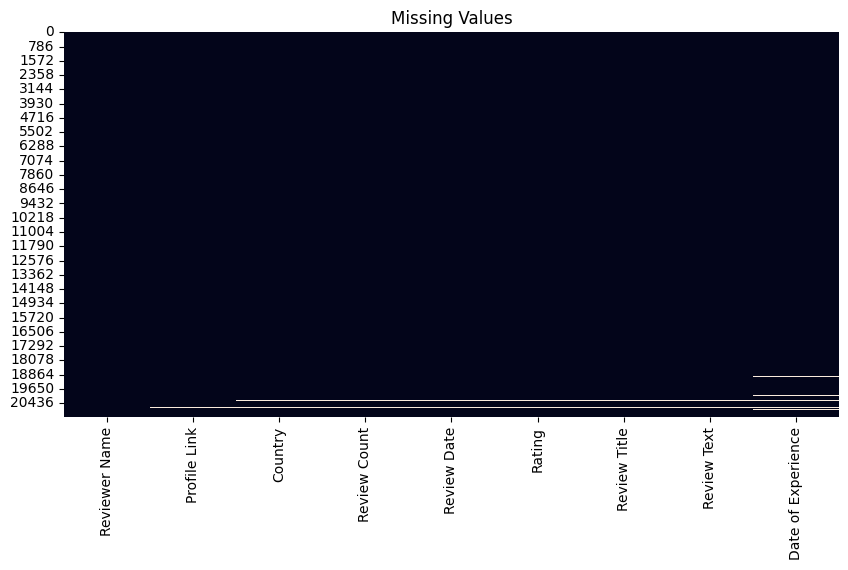

In [11]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

In [12]:
df = df.dropna(subset=["Rating", "Review Text"])

In [13]:
# Remove Duplicates
df.duplicated().sum()

np.int64(0)

In [14]:
# Clean the rating column
df["Rating"] = df["Rating"].str.extract(r"(\d+)").astype(float)

In [15]:
df["Rating"].value_counts().sort_index()

,count
Rating,
1.0,13123
2.0,1227
3.0,885
4.0,1292
5.0,4528


In [16]:
#Create SentimentLabel
def sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating <= 2:
        return "Negative"
    else:
        return "Neutral"

df["SentimentLabel"] = df["Rating"].apply(sentiment)

In [17]:
df["SentimentLabel"].value_counts()

,count
SentimentLabel,
Negative,14350
Positive,5820
Neutral,885


In [18]:
#Create ReviewLength
df["ReviewLength"] = df["Review Text"].apply(
    lambda x: len(str(x).split())
)

In [19]:
df[["Review Text", "ReviewLength"]].head()

,Review Text,ReviewLength
0,"I registered on the website, tried to order a ...",106
1,Had multiple orders one turned up and driver h...,53
2,I informed these reprobates that I WOULD NOT B...,122
3,I have bought from Amazon before and no proble...,82
4,If I could give a lower rate I would! I cancel...,100


In [20]:
#Create ReviewDate
df["Review Date"] = pd.to_datetime(
    df["Review Date"],
    errors="coerce"
)

In [21]:
df["Review Year"] = df["Review Date"].dt.year

In [22]:
df["Review Month"] = df["Review Date"].dt.month
df["Review Month Name"] = df["Review Date"].dt.month_name()

In [23]:
#Remove irrelevant columns
df = df.drop(columns=["Profile Link"])

In [24]:
df.columns

Index(['Reviewer Name', 'Country', 'Review Count', 'Review Date', 'Rating',
       'Review Title', 'Review Text', 'Date of Experience', 'SentimentLabel',
       'ReviewLength', 'Review Year', 'Review Month', 'Review Month Name'],
      dtype='object')

In [25]:
#Text preprocessing
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [26]:
def clean_text(text):

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Tokenization
    words = text.split()

    # Remove stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]

    # Lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
    ]

    return " ".join(words)

In [27]:
df["CleanReview"] = df["Review Text"].apply(clean_text)

In [28]:
df[["Review Text", "CleanReview"]].head()

,Review Text,CleanReview
0,"I registered on the website, tried to order a ...",registered website tried order laptop entered ...
1,Had multiple orders one turned up and driver h...,multiple order one turned driver phone door nu...
2,I informed these reprobates that I WOULD NOT B...,informed reprobate would going visit sick rela...
3,I have bought from Amazon before and no proble...,bought amazon problem happy service price amaz...
4,If I could give a lower rate I would! I cancel...,could give lower rate would cancelled amazon p...


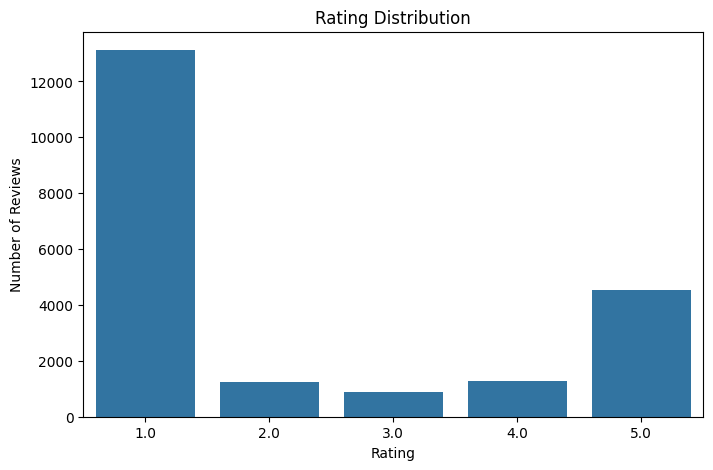

In [29]:
#Rating distribution
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

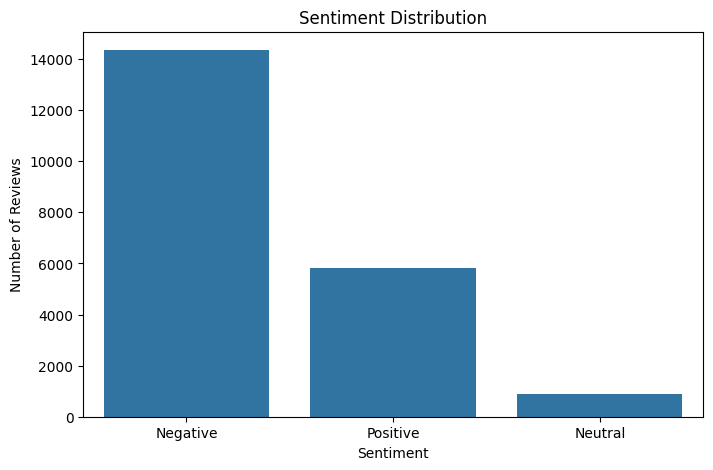

In [30]:
#Sentiment distribution
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="SentimentLabel")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [31]:
#Convert text into numerical values
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)

In [32]:
X = vectorizer.fit_transform(df["CleanReview"])

In [33]:
y = df["SentimentLabel"]

In [34]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [35]:
#train the ML model
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [36]:
#Make predictions
y_pred = model.predict(X_test)
y_pred[:10]

array(['Positive', 'Negative', 'Positive', 'Negative', 'Negative',
       'Negative', 'Negative', 'Negative', 'Positive', 'Negative'],
      dtype=object)

In [37]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8974115412016148


In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.91      0.96      0.94      2870
     Neutral       0.00      0.00      0.00       177
    Positive       0.86      0.87      0.86      1164

    accuracy                           0.90      4211
   macro avg       0.59      0.61      0.60      4211
weighted avg       0.86      0.90      0.88      4211



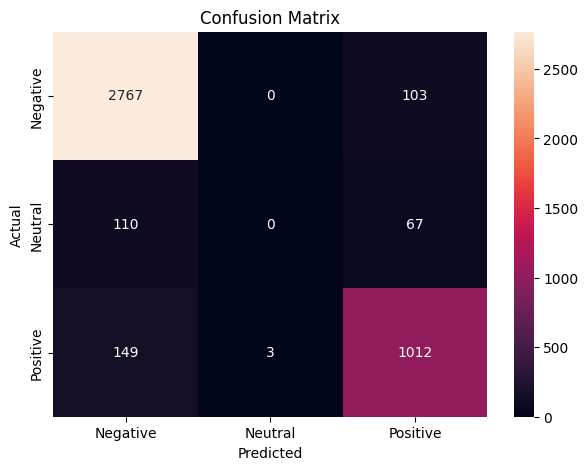

In [39]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [40]:
# Test your own review
new_review = [
    "This product is excellent. The quality is amazing and delivery was fast."
]

In [41]:
cleaned_review = [
    clean_text(new_review[0])
]

In [42]:
# transform
review_vector = vectorizer.transform(cleaned_review)

In [43]:
# predict
prediction = model.predict(review_vector)

print("Predicted Sentiment:", prediction[0])

Predicted Sentiment: Positive


In [44]:
# after traing
import joblib

joblib.dump(model, "sentiment_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [45]:
model = joblib.load("sentiment_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

In [46]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'streamlit.log', 'app.py', 'test_app.py', 'test_streamlit.log', 'sentiment_model.pkl', 'tfidf_vectorizer.pkl', '1785943249747-Amazon_Reviews.csv', 'sample_data']


In [47]:
import joblib

model = joblib.load("sentiment_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

print("✅ Model loaded")
print("✅ Vectorizer loaded")

✅ Model loaded
✅ Vectorizer loaded


In [48]:
review = "This product is excellent and I really love it."

review_vector = vectorizer.transform([review])

prediction = model.predict(review_vector)

print("Prediction:", prediction[0])

Prediction: Positive


In [49]:
%%writefile app.py

import streamlit as st
import joblib

st.set_page_config(
    page_title="Amazon Review Sentiment",
    page_icon="🛒"
)

st.title("🛒 Amazon Review Sentiment Analyzer")

st.write("Enter an Amazon product review below.")

model = joblib.load("sentiment_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

review = st.text_area(
    "Enter your review:",
    placeholder="Example: This product is very good!"
)

if st.button("🔍 Analyze Review"):

    if review.strip() == "":
        st.warning("Please enter a review.")

    else:

        review_vector = vectorizer.transform([review])

        prediction = model.predict(review_vector)[0]

        st.subheader("Prediction Result")

        st.write("Sentiment:", prediction)

Overwriting app.py


In [50]:
import os

print("app.py exists:", os.path.exists("app.py"))

app.py exists: True


In [51]:
!pip install streamlit -q

In [52]:
!nohup streamlit run app.py \
    --server.address=0.0.0.0 \
    --server.port=8501 \
    --server.headless=true \
    --server.enableCORS=false \
    --server.enableXsrfProtection=false \
    --browser.gatherUsageStats=false \
    > streamlit.log 2>&1 &

In [53]:
!cat streamlit.log

2026-08-16 22:41:43.061 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://104.196.115.199:8501



In [54]:
import requests

response = requests.get("http://127.0.0.1:8501")

print("Status:", response.status_code)

Status: 200


In [55]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print(url)

https://8501-m-s-kkb-use1d0-13nu4awcrfqkl-d.us-east1-0.prod.colab.dev


In [56]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
joblib
nltk

Writing requirements.txt


In [57]:
import os

for file in [
    "app.py",
    "sentiment_model.pkl",
    "tfidf_vectorizer.pkl",
    "requirements.txt"
]:
    print(file, "→", os.path.exists(file))

app.py → True
sentiment_model.pkl → True
tfidf_vectorizer.pkl → True
requirements.txt → True
